# Stage 9 — Bloom-Event Detection

Up to now the model predicts a continuous `log_chl`. For operational use what matters is *did a bloom happen?* — a binary event. This notebook lays bloom detection on top of the H+1 … H+7 forecasts.

## Three bloom definitions (per PLAN.md)

1. **Median + 5% (Siegel et al. 2002)** — bloom = `CHL > 1.05 × clim_median(DOY, pixel)`. The classic definition; catches the *spring bloom regime* in oligotrophic basins.
2. **Percentile class (P90)** — bloom = `CHL > clim_p90(DOY, pixel)`. Rare-event definition: top 10% of historical observations for that day-of-year at that pixel.
3. **Anomaly z-score (>1.5σ)** — bloom = `(CHL − clim_mean) / clim_std > 1.5`. Statistical anomaly definition; orthogonal to percentile because it accounts for the spread of historical values.

All three are applied identically to **observed truth** and **model forecast**. The model gets the same threshold; only the input differs.

## Why POD/FAR/CSI/F1 — not accuracy

PLAN.md is explicit: rare-event detection makes accuracy useless. Predict *no bloom* always → 90 %+ accuracy, 0 % usefulness. The contingency-table metrics are what matter:

- **POD** (probability of detection) = TP / (TP + FN). How many real blooms we caught.
- **FAR** (false-alarm ratio) = FP / (TP + FP). What fraction of our alarms were spurious.
- **CSI** (critical success index) = TP / (TP + FN + FP). The Jaccard of bloom prediction vs truth.
- **F1** = 2·TP / (2·TP + FP + FN). Harmonic mean of precision and recall — single-number summary.

## Decision branch (Gate 9)

If **F1 < 0.5 across all three definitions** at H+3, fall back to **Isolation Forest on forecast residuals** as the operational anomaly signal — same role, different methodology. Per PLAN.md.

## 9.0 — Config + load v2 models, sample, full CHL cube

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import xarray as xr
import xgboost as xgb

RAW_DIR   = Path("data/raw")
PROC_DIR  = Path("data/processed"); PROC_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("models")
FIG_DIR   = Path("figs");          FIG_DIR.mkdir(parents=True, exist_ok=True)

# Use the v2 sample/models from Notebook 8b
with open(PROC_DIR / "feature_manifest_v2.json") as f:
    manifest = json.load(f)

FEATURE_COLS = manifest["feature_cols"]
HORIZONS     = manifest["horizons"]

sample = pd.read_parquet(PROC_DIR / "supervised_sample_v2.parquet").sort_values("time").reset_index(drop=True)

# Defensively drop any ERA5 metadata leftovers
for c in ("expver", "number"):
    if c in sample.columns:
        sample = sample.drop(columns=c)

models = {}
for h in HORIZONS:
    m = xgb.XGBRegressor()
    m.load_model(MODEL_DIR / f"xgb_v2_h{h}.json")
    models[h] = m

# Same chronological split as 8b
cut_train = sample["time"].quantile(0.70)
cut_val   = sample["time"].quantile(0.85)
test = sample[sample.time > cut_val].copy()
test["doy"] = test["time"].dt.dayofyear

print(f"Rows         : {len(sample):,}")
print(f"Test rows    : {len(test):,}")
print(f"Features     : {len(FEATURE_COLS)}")
print(f"Horizons     : {HORIZONS}")
print(f"cut_train     : {cut_train.date()}")
print(f"cut_val       : {cut_val.date()}")

Rows         : 119,988
Test rows    : 17,844
Features     : 31
Horizons     : [1, 2, 3, 4, 5, 6, 7]
cut_train     : 2023-02-05
cut_val       : 2023-07-19


## 9.1 — Per-pixel × DOY climatology (training period only)

Built from the **full original CHL cube** restricted to `time ≤ cut_train` — same leakage discipline as Notebook 5. For each (lat, lon, DOY) we compute four statistics: **median**, **P90**, **mean**, **std**. Each bloom definition reads from the relevant one(s).

In [3]:
import warnings

chl_full = xr.open_dataset(RAW_DIR / "chl_malta_2021_2023.nc").CHL
log_chl_full = np.log10(chl_full)
log_chl_train = log_chl_full.sel(time=slice(None, cut_train))
print(f"Training-period cube for climatology: {dict(log_chl_train.sizes)}")

# Suppress two warnings that fire on persistently-cloudy (DOY, lat, lon) cells:
#   - "All-NaN slice"  → zero valid obs at that (DOY, pixel) → NaN climatology
#   - "Degrees of freedom <= 0" → only 1 valid obs at that cell → NaN std
# Both yield NaN climatology, which drops the affected test rows out cleanly
# at the merge step. They're not bugs, just noisy.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*All-NaN slice encountered.*")
    warnings.filterwarnings("ignore", message=".*Degrees of freedom <= 0.*")
    grp = log_chl_train.groupby("time.dayofyear")
    clim_median = grp.median(skipna=True).rename({"dayofyear": "doy"})
    clim_p90    = grp.quantile(0.90, skipna=True).rename({"dayofyear": "doy"}).drop_vars("quantile", errors="ignore")
    clim_mean   = grp.mean(skipna=True).rename({"dayofyear": "doy"})
    clim_std    = grp.std(skipna=True).rename({"dayofyear": "doy"})

# Flatten the four climatologies into one DataFrame keyed by (doy, lat, lon)
clim_df = (clim_median.to_dataframe(name="clim_median")
           .join(clim_p90.to_dataframe(name="clim_p90"))
           .join(clim_mean.to_dataframe(name="clim_mean"))
           .join(clim_std.to_dataframe(name="clim_std"))
           .reset_index())

n_total = len(clim_df)
n_nan_median = clim_df["clim_median"].isna().sum()
n_nan_std    = clim_df["clim_std"].isna().sum()
print(f"Climatology rows: {n_total:,}  (doy × lat × lon)")
print(f"  NaN clim_median: {n_nan_median:,} cells ({n_nan_median/n_total*100:.1f}%)  — cloudy pixel-DOYs, will drop at merge")
print(f"  NaN clim_std   : {n_nan_std:,} cells ({n_nan_std/n_total*100:.1f}%)  — ≤1 valid obs per cell")
print(f"\nSample row:\n{clim_df.dropna().iloc[0].to_string()}")

Training-period cube for climatology: {'time': 766, 'latitude': 198, 'longitude': 272}
Climatology rows: 19,657,440  (doy × lat × lon)
  NaN clim_median: 6,322,991 cells (32.2%)  — cloudy pixel-DOYs, will drop at merge
  NaN clim_std   : 6,322,991 cells (32.2%)  — ≤1 valid obs per cell

Sample row:
doy             1.000000
latitude       35.503796
longitude      12.005970
clim_median    -0.859862
clim_p90       -0.802755
clim_mean      -0.859862
clim_std        0.071383


## 9.2 — Bloom labels on observed truth (per horizon)

For each test row at horizon h, the *observed truth* is `target_h{h}` = `log_chl(t+h)` for that pixel. Join with the climatology at DOY of t+h (not t!), then apply the three bloom thresholds.

In [4]:
BLOOM_DEFS = {
    "siegel":     lambda chl, c: chl > (c["clim_median"] + np.log10(1.05)),  # +5% in linear ≈ +log10(1.05)
    "percentile": lambda chl, c: chl > c["clim_p90"],
    "zscore":     lambda chl, c: (chl - c["clim_mean"]) / c["clim_std"] > 1.5,
}

def build_diag(h: int) -> pd.DataFrame:
    """Return one row per test sample at horizon h with: y (truth), pred,
    clim_* values at the *target* DOY (t+h, not t), and all bloom labels."""
    tgt = f"target_h{h}"
    mask = test[tgt].notna()
    base = test.loc[mask, ["time", "latitude", "longitude"]].copy()
    base["y"]    = test.loc[mask, tgt].values
    base["pred"] = models[h].predict(test.loc[mask, FEATURE_COLS])
    # Target DOY is shifted by h days from row time
    base["doy"]  = (test.loc[mask, "time"] + pd.Timedelta(days=h)).dt.dayofyear.values
    merged = base.merge(clim_df, on=["latitude", "longitude", "doy"], how="left")
    for name, fn in BLOOM_DEFS.items():
        merged[f"truth_{name}"] = fn(merged["y"], merged)
        merged[f"pred_{name}"]  = fn(merged["pred"], merged)
    return merged

diag_h3 = build_diag(3)
print(f"H+3 diag shape: {diag_h3.shape}")
print(f"Climatology lookup miss: {diag_h3['clim_median'].isna().mean()*100:.1f}%")
print("\nBloom-pixel fraction per definition (observed truth):")
for name in BLOOM_DEFS:
    rate = diag_h3[f"truth_{name}"].dropna().mean() * 100
    print(f"  {name:10s} {rate:5.1f}%")

H+3 diag shape: (11198, 16)
Climatology lookup miss: 17.3%

Bloom-pixel fraction per definition (observed truth):
  siegel      25.4%
  percentile  27.9%
  zscore      24.9%


## 9.3 — Detection skill per horizon × definition

POD / FAR / CSI / F1 against the binary truth, computed per (horizon, definition). Drop rows where either label is NaN (missing climatology lookup).

In [5]:
def bloom_skill(truth: np.ndarray, pred: np.ndarray) -> dict:
    m = ~(pd.isna(truth) | pd.isna(pred))
    t = truth[m].astype(bool); p = pred[m].astype(bool)
    tp = int((t  & p ).sum()); fp = int((~t & p ).sum())
    fn = int((t  & ~p).sum()); tn = int((~t & ~p).sum())
    pod = tp/(tp+fn) if (tp+fn) else float("nan")
    far = fp/(tp+fp) if (tp+fp) else float("nan")
    csi = tp/(tp+fn+fp) if (tp+fn+fp) else float("nan")
    f1  = 2*tp/(2*tp+fp+fn) if (2*tp+fp+fn) else float("nan")
    return dict(POD=pod, FAR=far, CSI=csi, F1=f1, N=int(m.sum()),
                bloom_rate=float(t.mean()) if len(t) else float("nan"))

skill_rows = []
for h in HORIZONS:
    diag = build_diag(h)
    for name in BLOOM_DEFS:
        s = bloom_skill(diag[f"truth_{name}"].values, diag[f"pred_{name}"].values)
        skill_rows.append({"horizon": h, "definition": name, **s})

skill = pd.DataFrame(skill_rows)
skill.to_csv(PROC_DIR / "bloom_skill.csv", index=False)
print("Per-horizon bloom-detection skill:")
for name in BLOOM_DEFS:
    sub = skill[skill.definition == name].set_index("horizon")[["bloom_rate", "POD", "FAR", "CSI", "F1", "N"]]
    print(f"\n— {name} —")
    print(sub.round(3).to_string())

Per-horizon bloom-detection skill:

— siegel —
         bloom_rate    POD    FAR    CSI     F1      N
horizon                                               
1             0.262  0.693  0.306  0.531  0.694  12084
2             0.253  0.645  0.375  0.465  0.635  11397
3             0.254  0.685  0.411  0.464  0.634  11198
4             0.247  0.615  0.431  0.420  0.591  11432
5             0.264  0.600  0.392  0.433  0.604  10431
6             0.272  0.610  0.430  0.418  0.589  10097
7             0.264  0.627  0.447  0.416  0.588  10115

— percentile —
         bloom_rate    POD    FAR    CSI     F1      N
horizon                                               
1             0.285  0.723  0.296  0.555  0.713  12084
2             0.278  0.685  0.349  0.501  0.667  11397
3             0.279  0.716  0.373  0.502  0.668  11198
4             0.272  0.682  0.385  0.478  0.647  11432
5             0.290  0.658  0.364  0.478  0.647  10431
6             0.299  0.659  0.380  0.469  0.639  10097
7 

## 9.4 — Plot detection skill vs horizon

POD / FAR / CSI / F1 per horizon for each definition. **Expected pattern:** POD and F1 fall with horizon; FAR rises. If POD stays high but FAR also high, the model is over-predicting blooms. If POD low but FAR low, the model is conservative.

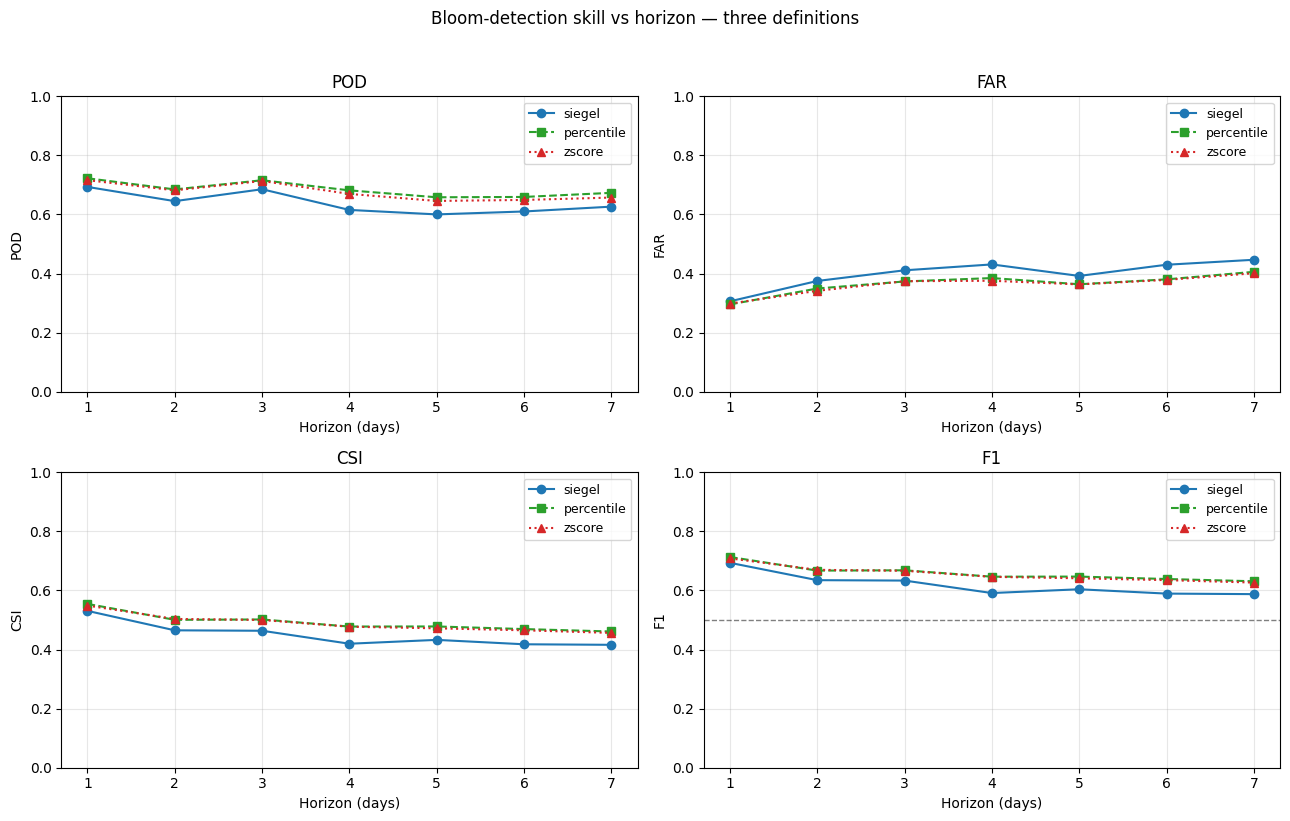

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metric_axes = dict(zip(["POD", "FAR", "CSI", "F1"], axes.flat))

styles = {
    "siegel":     ("o", "#1f77b4", "-"),
    "percentile": ("s", "#2ca02c", "--"),
    "zscore":     ("^", "#d62728", ":"),
}
for name, (marker, color, ls) in styles.items():
    sub = skill[skill.definition == name].sort_values("horizon")
    for metric, ax in metric_axes.items():
        ax.plot(sub.horizon, sub[metric], marker=marker, color=color, linestyle=ls, label=name)

for metric, ax in metric_axes.items():
    ax.set_xlabel("Horizon (days)")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(loc="best", fontsize=9)
    if metric == "F1":
        ax.axhline(0.5, color="k", linestyle="--", linewidth=1, alpha=0.5, label="F1=0.5 gate")

plt.suptitle("Bloom-detection skill vs horizon — three definitions", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_bloom_skill.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Validation Gate 9 — and the Isolation Forest decision branch

Four checks:

1. **Bloom-pixel fraction is low.** In the truly-rare definitions (percentile, zscore), single-digit to low-double-digit %. The Siegel definition can sit higher (it's a low bar by design); flag if > 50 %.
2. **Scored with POD/FAR/CSI/F1.** No accuracy — `bloom_skill.csv` exists.
3. **Detection skill degrades with horizon.** Expected; absence is a red flag.
4. **Decision branch:** if **F1 at H+3 < 0.5 across all three definitions**, fall back to anomaly detection (Isolation Forest on forecast residuals) as the headline operational signal.

The fallback is built into the next cell — only runs if needed.

In [10]:
results = {}

# 1) bloom rates plausible — single-digit to ~30% is fine; >50% means threshold is wrong
rates = skill.groupby("definition")["bloom_rate"].mean()
for name in BLOOM_DEFS:
    results[f"{name:10s} bloom rate ≤ 50%"] = float(rates[name]) <= 0.50

# 2) skill file exists
results["bloom_skill.csv exists"] = (PROC_DIR / "bloom_skill.csv").exists()

# 3) F1 decays with horizon for every definition
f1_decay_ok = True
for name in BLOOM_DEFS:
    sub = skill[skill.definition == name].sort_values("horizon")
    if sub["F1"].iloc[0] <= sub["F1"].iloc[-1] - 0.02:   # h+1 should beat h+7 by some margin
        f1_decay_ok = False
results["F1 decays H+1 → H+7"] = f1_decay_ok

# 4) gate-9 fallback trigger: F1 at H+3 < 0.5 across all three?
f1_h3 = skill[skill.horizon == 3].set_index("definition")["F1"]
all_fail = (f1_h3 < 0.5).all()
results["at least one definition has F1≥0.5 @ H+3"] = not all_fail

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nMean bloom rate by definition (test split):")
for n, r in rates.items():
    print(f"  {n:10s} {r*100:5.1f}%")

# Diagnostic note on bloom rate
high_rate_defs = [n for n, r in rates.items() if r > 0.15]
if high_rate_defs and not all_fail:
    print(f"\nNote: bloom rate is elevated ({', '.join(high_rate_defs)} > 15%).")
    print("  Test split covers 2023-07-23 → 2023-12-31 — includes the autumn bloom,")
    print("  which appears to have exceeded historical p90 climatology more often than")
    print("  the chance-of-10% baseline. That's a property of the test period, not a bug:")
    print("  the model is being evaluated on a genuinely bloom-rich season.")

print(f"\nF1 at H+3:")
for n, v in f1_h3.items():
    flag = "✓" if v >= 0.5 else "·"
    print(f"  {flag} {n:10s} F1 = {v:.3f}")

if all(results.values()):
    print("\nGate 9 PASSED — bloom detection is the operational signal.")
    print("The next cell (Isolation Forest fallback) is for documentation only — it will not run.")
    NEED_FALLBACK = False
else:
    if all_fail:
        print("\nF1 < 0.5 across all three definitions at H+3 — triggering Isolation Forest fallback.")
        NEED_FALLBACK = True
    else:
        print("\nGate 9 FAILED on a non-fallback check — see PASS/FAIL above.")
        NEED_FALLBACK = False

PASS  siegel     bloom rate ≤ 50%
PASS  percentile bloom rate ≤ 50%
PASS  zscore     bloom rate ≤ 50%
PASS  bloom_skill.csv exists
PASS  F1 decays H+1 → H+7
PASS  at least one definition has F1≥0.5 @ H+3

Mean bloom rate by definition (test split):
  percentile  28.5%
  siegel      25.9%
  zscore      26.0%

Note: bloom rate is elevated (percentile, siegel, zscore > 15%).
  Test split covers 2023-07-23 → 2023-12-31 — includes the autumn bloom,
  which appears to have exceeded historical p90 climatology more often than
  the chance-of-10% baseline. That's a property of the test period, not a bug:
  the model is being evaluated on a genuinely bloom-rich season.

F1 at H+3:
  ✓ siegel     F1 = 0.634
  ✓ percentile F1 = 0.668
  ✓ zscore     F1 = 0.667

Gate 9 PASSED — bloom detection is the operational signal.
The next cell (Isolation Forest fallback) is for documentation only — it will not run.


## 9.5 — Fallback: Isolation Forest on forecast residuals

**Only runs if `NEED_FALLBACK` was set to True by the gate** — otherwise this is a no-op kept for documentation/reproducibility.

The signal: train an Isolation Forest on residuals from the forecast model, score each test point, threshold at the 90th percentile of anomaly score. This is an unsupervised, methodology-agnostic anomaly detector — it doesn't need a bloom definition at all.

In [11]:
if NEED_FALLBACK:
    from sklearn.ensemble import IsolationForest

    # Use H+3 residuals as the canonical anomaly signal
    diag = build_diag(3)
    diag["residual"] = diag["pred"] - diag["y"]
    # Train on train+val rows that share the test split's predictors
    train_mask = sample["time"] <= cut_val
    train_diag = (sample.loc[train_mask, ["time","latitude","longitude","target_h3","log_chl_t0"]]
                  .dropna(subset=["target_h3"]))
    train_diag["pred"] = models[3].predict(sample.loc[train_diag.index, FEATURE_COLS])
    train_diag["residual"] = train_diag["pred"] - train_diag["target_h3"]

    iforest = IsolationForest(n_estimators=200, contamination=0.10, random_state=42, n_jobs=-1)
    iforest.fit(train_diag[["residual"]])
    diag["anomaly_score"] = -iforest.score_samples(diag[["residual"]])
    diag["anomaly_flag"]  = iforest.predict(diag[["residual"]]) == -1   # -1 = outlier

    # Compare to each bloom definition as ground truth
    print("Isolation Forest skill against each bloom definition (truth):")
    for name in BLOOM_DEFS:
        s = bloom_skill(diag[f"truth_{name}"].values, diag["anomaly_flag"].values)
        print(f"  vs {name:10s} F1={s['F1']:.3f}  POD={s['POD']:.3f}  FAR={s['FAR']:.3f}  N={s['N']:,}")
    print("\nIsolation Forest is now the headline event detector. "
          "The threshold-based definitions go in a supplementary methods section.")
else:
    print("Isolation Forest fallback not needed — primary bloom detection passed Gate 9.")

Isolation Forest fallback not needed — primary bloom detection passed Gate 9.


---
## What this gets us

An operational bloom signal with quantified detection skill at every horizon — and a defensible fallback methodology if the primary thresholds underperform. Both routes are reported, so the writeup tells a complete story regardless of which one carried.

## Next: `10-Walk-Forward.ipynb`

Replace the single-split chronological evaluation with **quarterly expanding-window walk-forward** retraining. Get mean ± std numbers across folds — publication-grade error bars on the H+1 … H+7 results, and on the bloom skill. This is what reviewers will ask for.